# 1 Набор данных

CSV-файл с часовым разрешением (каждая строка — один час), период с 01.01.2024 по 31.12.2025 по времени Будапешта. В столбце timestamp время указано в UTC, поэтому первая строка — 2023-12-31 23:00 UTC.


**Задача: прогнозирование цены на wholesale рынке электроэнергии Венгрии (Day-Ahead)**

**Целевая переменная:
price_eur_mwh** — цена электроэнергии на рынке на сутки вперёд (Day-Ahead), €/МВт·ч.
Цена может быть очень низкой и даже отрицательной, особенно в солнечные часы.

**Признаки** (все это прогнозы на сутки вперёд, известные заранее):

*demand_forecast_mwh* — потребление электроэнергии, МВт·ч

*solar_forecast_mwh* — выработка солнечных станций, МВт·ч

*wind_forecast_mwh* — выработка ветровых станций, МВт·ч

*nuclear_forecast_mwh* — выработка АЭС, МВт·ч

*temperature_forecast_c* — температура, °C

*net_exchange_forecast_mwh* — чистый экспорт (перетоки с соседними странами), МВт·ч.

# 2 Import библиотек

In [2]:
import pandas as pd # Библиотека Pandas для работы с табличными данными
from google.colab import files  # чтобы загружать файлы в облако через проводник

import numpy as np # библиотека Numpy для операций линейной алгебры и прочего
import matplotlib.pyplot as plt # библиотека MatPlotLib для визуализации
import seaborn as sns; sns.set() # библиотека Seaborn для визуализации данных из Pandas
import holidays

import os
import sklearn
import statsmodels
import matplotlib.pyplot as plt
import plotly
from statsmodels.tsa.seasonal import seasonal_decompose

import matplotlib.dates as mdates#Date Parser
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
sns.set_style('white')
sns.set(rc={'figure.figsize':(11, 4)})

import warnings
#предупреждение  печати statsmodels (verbose)
warnings.filterwarnings("ignore", category=FutureWarning, module="statsmodels")

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Загрузка данных

In [ ]:
uploaded = files.upload() #просто запускаем и выбираем файл в проводнике

Saving data_with_features.csv to data_with_features.csv


# Считываем файл в DataFrame



метод `.read_csv(path,delimiter)`

In [4]:
df = pd.read_csv('/content/drive/MyDrive/year_project/data_with_features.csv', delimiter = ',') # Открываем загруженный файл, через полный путь к файлу (с именем)
df # В этом блокноте мы работаем с данными без дубликатов

,timestamp,price_eur_mwh,demand_forecast_mwh,solar_forecast_mwh,net_exchange_forecast_mwh,wind_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c
0,2023-12-31 23:00:00+00:00,0.10,4068.18,0.0,-1089.2,86.58,1900.0,5.28
1,2024-01-01 00:00:00+00:00,0.01,3892.38,0.0,-971.5,57.10,1900.0,5.37
2,2024-01-01 01:00:00+00:00,0.04,3644.58,0.0,-860.7,44.13,1900.0,5.49
3,2024-01-01 02:00:00+00:00,0.01,3493.50,0.0,-733.1,65.15,1900.0,5.57
4,2024-01-01 03:00:00+00:00,0.01,3454.03,0.0,-700.0,93.58,1900.0,5.53
...,...,...,...,...,...,...,...,...
17539,2025-12-31 18:00:00+00:00,124.37,5407.65,0.0,-2105.8,113.10,1920.0,-2.72
17540,2025-12-31 19:00:00+00:00,115.53,5257.10,0.0,-1944.2,122.05,1920.0,-2.60
17541,2025-12-31 20:00:00+00:00,113.56,5308.78,0.0,-1999.6,132.15,1920.0,-2.44
17542,2025-12-31 21:00:00+00:00,108.72,5326.05,0.0,-1974.3,138.50,1920.0,-2.29


# EDA - Разведывательный анализ данных.

Цель разведывательного анализа данных - попытка предварительного понимания того, с чем вы имеете дело. Например, результатами анализа могут быть удаление аномалий, заполнение (удаление) пропусков, визуализация данных, выделение признаков или получение (или преобразование) новых признаков, удаление некоторых шумов, помех или других нерегулярных значений.


In [5]:
df.info() # информация о данных в датафрейме: сколько строк, какие данные в столбцах, сколько пропущенных значений (Nan-values)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   timestamp                  17544 non-null  object 
 1   price_eur_mwh              17544 non-null  float64
 2   demand_forecast_mwh        17544 non-null  float64
 3   solar_forecast_mwh         17544 non-null  float64
 4   net_exchange_forecast_mwh  17544 non-null  float64
 5   wind_forecast_mwh          17544 non-null  float64
 6   nuclear_forecast_mwh       17544 non-null  float64
 7   temperature_forecast_c     17544 non-null  float64
dtypes: float64(7), object(1)
memory usage: 1.1+ MB


 В данных нет пропусков, все признаки кроме timestamp представляют собой числовые признаки. Целевая переменная также является числовой величиной

In [6]:
# Для удобства работы с числовыми признаками
time_columns = [] # создаем пустой список для имен колонок временных данных
num_columns = [] # создаем пустой список для имен колонок числовых данных

for column_name in df.columns: # смотрим на все колонки в датафрейме
    if (df[column_name].dtypes == object): # проверяем тип данных для каждой колонки
        time_columns +=[column_name] # если тип объект - то складываем в категориальные данные
    else:
        num_columns +=[column_name] # иначе - числовые

# важно: если признак категориальный, но хранится в формате числовых данных, тогда код не сработает корректно


# выводим результат
print(' Время данные:\t ',time_columns, '\n Число столблцов = ',len(time_columns))

print('Числовые данные:\t ',  num_columns, '\n Число столблцов = ',len(num_columns))


 Время данные:	  ['timestamp'] 
 Число столблцов =  1
Числовые данные:	  ['price_eur_mwh', 'demand_forecast_mwh', 'solar_forecast_mwh', 'net_exchange_forecast_mwh', 'wind_forecast_mwh', 'nuclear_forecast_mwh', 'temperature_forecast_c'] 
 Число столблцов =  7


# 3 Анализ числовых признаков

Статистика по числовым данным

метод `.describe()`

In [7]:
df.describe() # посчитает "стандартные" статистические параметры для числовых данных
# если данные с типом отличных от числовых - то они проигнорируются

,price_eur_mwh,demand_forecast_mwh,solar_forecast_mwh,net_exchange_forecast_mwh,wind_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c
count,17544.000000,17544.000000,17544.000000,17544.000000,17544.000000,17544.000000,17544.000000
mean,104.658552,4932.654702,709.517923,-1096.129697,66.320306,1740.107361,12.610484
std,73.143194,849.932015,1021.831947,1332.193201,61.657125,222.590801,9.351000
min,-210.050000,2303.430000,0.000000,-5365.300000,0.550000,1372.250000,-7.030000
25%,72.830000,4290.282500,0.000000,-2064.225000,16.522500,1440.000000,4.880000
50%,97.675000,4860.755000,34.925000,-1299.750000,47.130000,1900.000000,12.050000
75%,126.352500,5504.685000,1266.182500,-219.200000,97.457500,1900.000000,19.990000
max,999.010000,7442.800000,4329.080000,3819.900000,291.830000,1949.500000,35.910000


рассмотрим гистограммы (распределение) значений по каждому числовому признаку (столбцу)

Гистограмма seaborn  `.histplot(data, x, bins)`

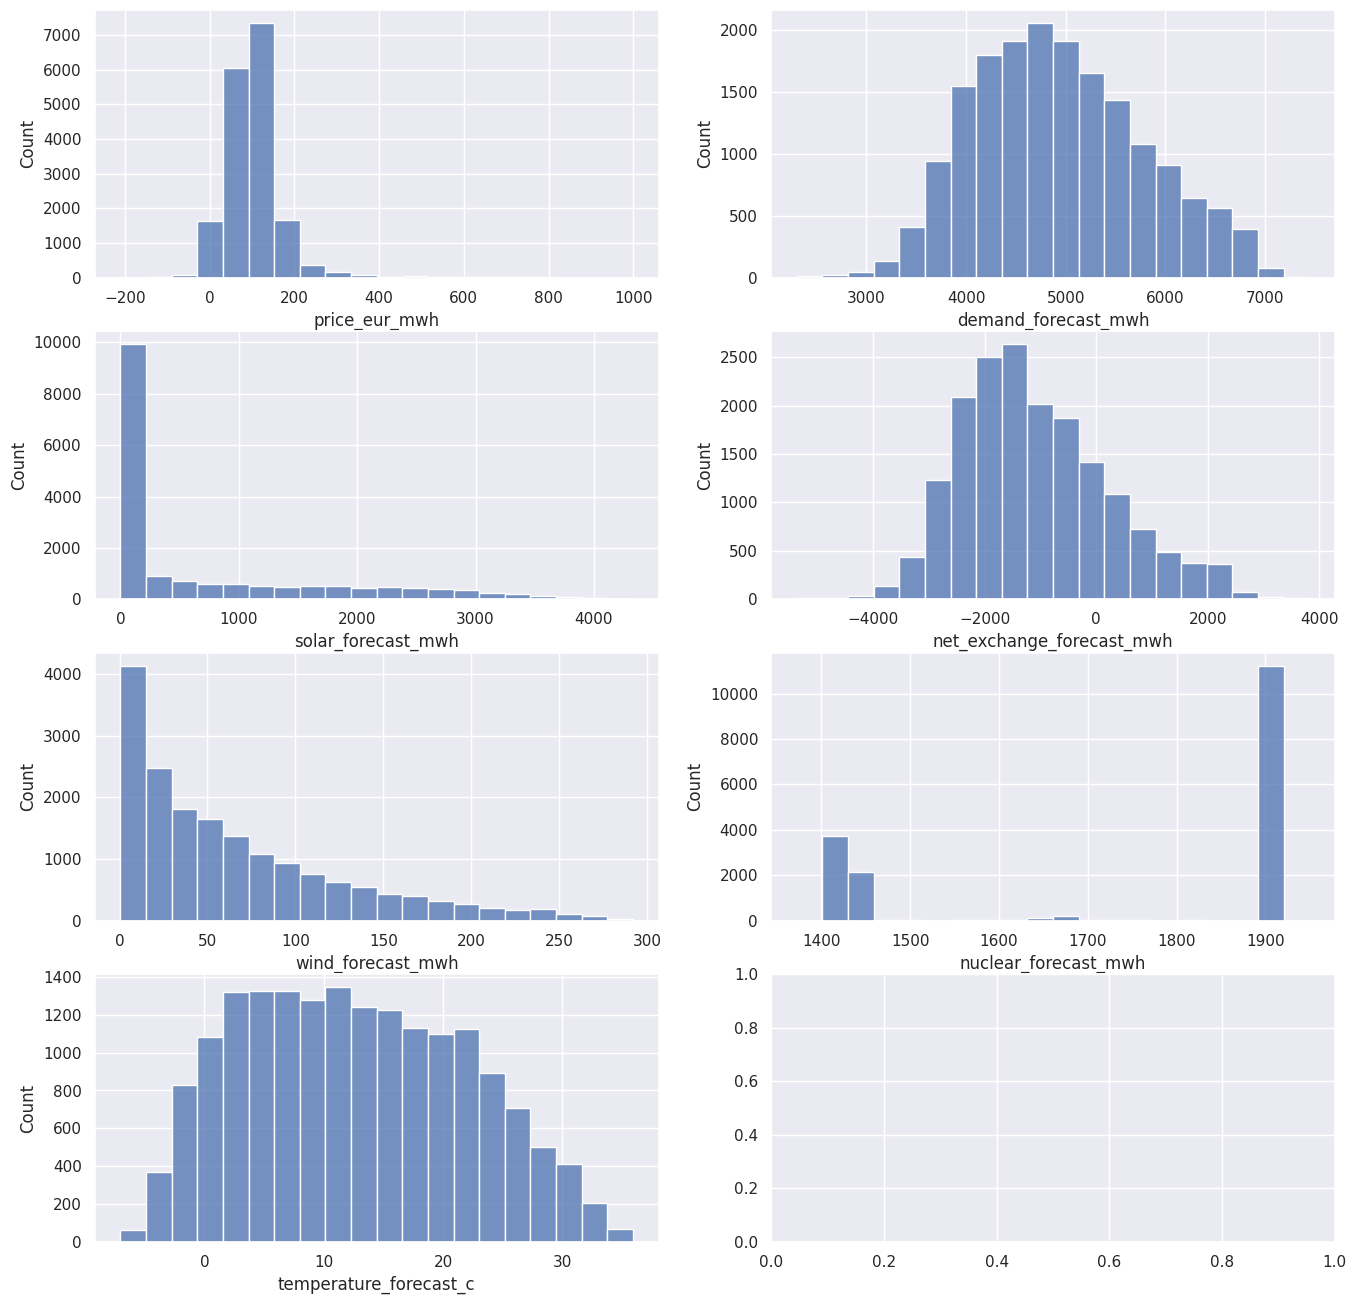

In [8]:
width = 2
height = int(np.ceil(len(num_columns)/width))
fig, ax = plt.subplots(nrows=height, ncols=width, figsize=(16,16)) # создаем "полотно", на котором будем "рисовать" графики
#     ↑  более точная структура (почти синоним subplot). Говорим что у нас будет height строк и width столбцов

for idx, column_name in enumerate(num_columns): # перебираем все числовые данные
    plt.subplot(height,width, idx+1) #берем конкретную ячейку из заранее подготовленную заготовку
    # рисуем с помощью библиотеки seaborn
    sns.histplot(data=df, # какой датафрейм используем
            x=column_name, # какую переменную отрисовываем
            bins = 20);  # на сколько ячеек разбиваем

#### Выводы по построенным гистограммам: возможно столбцы nuclear_forecast_mwh и solar__forecast_mwh имеют аномалии. Распределение wind_forecast_mwh является экспоненциальным. Распределение остальных Неупомянутых данных кроме целевой переменной близко к нормальному. Скорее всего для более корректных выводов нужно смотреть зависимость целевой переменной и признаков от времени.

Посмотрим на столбцы nuclear_forecast_mwh и solar_forecast_mwh в логарифмическом масштабе.

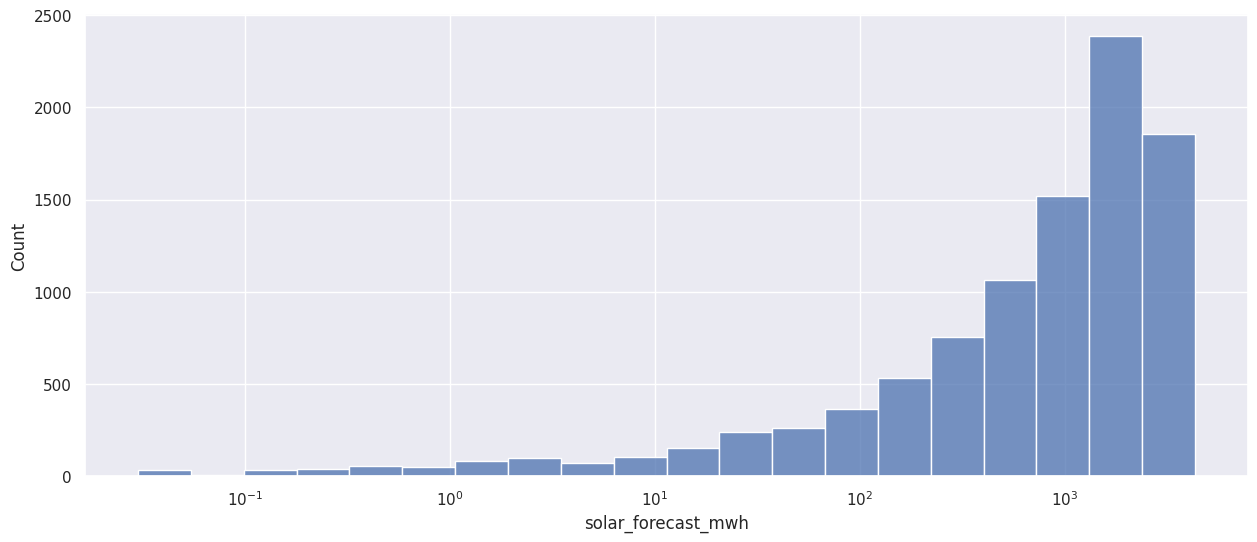

In [ ]:
plt.figure(figsize=(15,6)) # создаем "полотно", уточняем размер
sns.histplot(data=df, # какой датафрейм используем
             x='solar_forecast_mwh', # какую переменную отрисовываем
             bins = 20, # на сколько ячеек разбиваем
             log_scale = True); # захотели использовать логарифмический масштаб (для очень больших диапазонов)

#### Выводы по построенным гистограммам: В логарифмическом масштабе solar__forecast_mwh имеет распределение близкое к  нормальному. Неообходимо также посмотреть другие признаки в логарифмическом масштабе

## 4 Предварительная Обработка

## Нормализация

In [20]:
DF_norm  = df.copy() # чтобы не портить исходный датафрейм - складываем копию датафрейма в новый датафрейм
Xmin = df[num_columns].min() # находим минимум (для каждого числового признака)
Xmax = df[num_columns].max() # находим максимум (для каждого числового признака)
                                                # ↓ каждый столбец делится на свою разницу максимума и минимума
DF_norm[num_columns] = (df[num_columns]- Xmin)/( Xmax - Xmin) # реализуем нормализацию. матричные операции работают
                                        # ↑ из каждого стобца вычитаем свой минимум

In [14]:
DF_norm.to_csv('/content/drive/MyDrive/year_project/data_normalized.csv', index=False)

## Стандартизация

In [15]:
DF_scaled = df.copy() # чтобы не портить исходный датафрейм - складываем копию датафрейма в новый датафрейм
M = df[num_columns].mean() # находим среднее (для каждого числового признака)
STD = df[num_columns].std() # находим стандартное отклонение (для каждого числового признака)
DF_scaled[num_columns] = (df[num_columns]-M)/STD # реализуем стандартизацию. матричные операции работают

In [16]:
DF_scaled.to_csv('/content/drive/MyDrive/year_project/data_scaled.csv', index=False)

## Нелинейное преобразование



Сначала логарифмирование, потом стандартизация

In [17]:
DF_power  = df.copy() # чтобы не портить исходный датафрейм - складываем копию датафрейма в новый датафрейм
DF_power[num_columns] = np.log(DF_power[num_columns]) # натуральный логарифм применится ко всем  столбцам, которые мы укажем
# ниже как при стандартизации
M = DF_power[num_columns].mean()
STD = DF_power[num_columns].std()
DF_power[num_columns] = (DF_power[num_columns]-M)/STD

/usr/local/lib/python3.13/dist-packages/pandas/core/internals/blocks.py:393: RuntimeWarning: divide by zero encountered in log
  result = func(self.values, **kwargs)
/usr/local/lib/python3.13/dist-packages/pandas/core/internals/blocks.py:393: RuntimeWarning: invalid value encountered in log
  result = func(self.values, **kwargs)


In [19]:
DF_power.to_csv('/content/drive/MyDrive/year_project/data_powered.csv', index=False)

## 5 Конструирование признаков



**Базовые балансовые признаки**

Цена электроэнергии сильно зависит от баланса «спрос — предложение». Есть прогнозы выработки по источникам и прогноз спроса, но полезно явно посчитать чистые величины:

supply_forecast_mwh = solar_forecast_mwh + wind_forecast_mwh + nuclear_forecast_mwh — ***суммарная генерация по этим источникам**.

net_supply_forecast_mwh = supply_forecast_mwh + net_exchange_forecast_mwh — **предложение с учётом перетоков**.

demand_supply_gap_mwh = demand_forecast_mwh - net_supply_forecast_mwh — **«дефицит/профицит» мощности**. Это один из самых сильных признаков: большой профицит (особенно из-за солнца/ветра) часто ведёт к низкой или отрицательной цене.

renewables_share = (solar_forecast_mwh + wind_forecast_mwh) / (supply_forecast_mwh + 1e-6) — **доля ВИЭ в прогнозируемой генерации**. Высокая доля ВИЭ часто коррелирует с отрицательными ценами в дневные часы.

**Относительные и нормированные признаки**

Модели (особенно линейные и деревья) любят признаки в понятном масштабе:

demand_per_temp = demand_forecast_mwh / (abs(temperature_forecast_c) + 1) — **спрос на единицу температуры** (помогает учесть нелинейности при экстремальных температурах).

solar_per_demand = solar_forecast_mwh / (demand_forecast_mwh + 1e-6) и аналогично wind_per_demand — **доля солнечной/ветровой генерации относительно спроса**.

nuclear_share = nuclear_forecast_mwh / (supply_forecast_mwh + 1e-6) — **доля базовой генерации** (АЭС обычно работают стабильно, это помогает модели понять «жёсткую» часть предложения).

**Временные и календарные признаки**
Даже если нет времени суток в явном виде, его почти всегда нужно добавить:

hour_of_day (0–23), day_of_week (0–6), is_weekend (бинарный), month — **сезонные и недельные паттерны цен** очень выражены.

is_holiday (бинарный) — **национальные праздники** часто дают аномальные цены.

hour_sin, hour_cos — **тригонометрическое кодирование часа суток** (чтобы модель корректно обрабатывала цикличность: 23 и 0 близки).

day_sin, day_cos — **аналогично для дня года**.

Если данные идут по часам, эти признаки критически важны: отрицательные цены чаще всего бывают днём, когда солнце активно, а спрос ещё не максимален.



**Признаки на основе температуры (погодные эффекты)**

Температура влияет и на спрос (отопление/охлаждение), и косвенно на цену:

temp_squared = temperature_forecast_c ** 2 — **нелинейный эффект:** при очень низких или высоких температурах спрос растёт непропорционально.
is_cold = (temperature_forecast_c < threshold) и is_hot = (temperature_forecast_c > threshold) — бинарные пороги (например, < 5°C и > 25°C), чтобы модель явно видела экстремальные режимы.
Если есть данные за прошлые дни, можно добавить temp_change_24h — изменение температуры за сутки, потому что резкий рост/падение температуры сильно меняет спрос.

**Перетоки и внешние рынки**

Есть net_exchange_forecast_mwh, но можно добавить:

net_export_share = net_exchange_forecast_mwh / (demand_forecast_mwh + 1e-6) — насколько экспорт/импорт значим относительно внутреннего спроса.

**Производные и агрегированные признаки по ВИЭ**

Поскольку отрицательные цены часто связаны с солнечной генерацией:

solar_vs_demand = solar_forecast_mwh / (demand_forecast_mwh + 1e-6) — **ключевой индикатор риска низкой цены**.
wind_vs_demand, solar_plus_wind_vs_demand — **суммарный вклад переменных ВИЭ относительно спроса**.

Если данные почасовые, **полезно добавить скользящие агрегаты: solar_mean_prev_24h, solar_max_prev_24h, solar_min_prev_24h** — чтобы модель видела не только прогноз, но и недавнюю динамику.

**Индикаторы «риска отрицательной цены»**

**Можно явно сконструировать бинарные признаки**, которые подсказывают модели, когда цена может быть отрицательной:

**high_solar_condition = (solar_forecast_mwh > demand_forecast_mwh * 0.7)** — например, если солнечная генерация покрывает большую часть спроса, риск отрицательной цены высок.

Аналогично можно сделать **high_renewables_condition на базе суммы солнца и ветра**.
Такие признаки не заменяют модель, но помогают деревьям быстрее находить нужные правила.

**Сезонные и трендовые признаки**


trend_index — простой линейный тренд (номер дня от начала выборки), чтобы модель могла учесть долгосрочные изменения цен.
seasonal_index (например, номер недели в году) — чтобы учесть годовые циклы.

In [28]:
from pathlib import Path

In [30]:
def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Конструирует дополнительные признаки для прогнозирования цены электроэнергии.
    Вход: DataFrame с колонками demand_forecast_mwh, solar_forecast_mwh,
          wind_forecast_mwh, nuclear_forecast_mwh, temperature_forecast_c,
          net_exchange_forecast_mwh. Также должна быть колонка datetime
          (или hour — час суток).
    Выход: DataFrame с новыми признаками.
    """
    df_new_feature = df.copy()

    # --- Баланс спроса и предложения ---
    df_new_feature['supply_forecast_mwh'] = (
        df_new_feature['solar_forecast_mwh']
        + df_new_feature['wind_forecast_mwh']
        + df_new_feature['nuclear_forecast_mwh']
    )

    df_new_feature['net_supply_forecast_mwh'] = (
        df_new_feature['supply_forecast_mwh'] + df_new_feature['net_exchange_forecast_mwh']
    )

    # Дефицит/профицит: положительный — дефицит, отрицательный — профицит
    df_new_feature['demand_supply_gap_mwh'] = (
        df_new_feature['demand_forecast_mwh'] - df_new_feature['net_supply_forecast_mwh']
    )

    # Доля ВИЭ (солнце + ветер) в прогнозируемой генерации
    denom = df_new_feature['supply_forecast_mwh'] + 1e-6
    df_new_feature['renewables_share'] = (
        (df_new_feature['solar_forecast_mwh'] + df_new_feature['wind_forecast_mwh']) / denom
    )
    df_new_feature['nuclear_share'] = df_new_feature['nuclear_forecast_mwh'] / denom

    # --- Относительные признаки (на единицу спроса) ---
    denom_demand = df_new_feature['demand_forecast_mwh'] + 1e-6
    df_new_feature['solar_per_demand'] = df_new_feature['solar_forecast_mwh'] / denom_demand
    df_new_feature['wind_per_demand'] = df_new_feature['wind_forecast_mwh'] / denom_demand
    df_new_feature['renewables_per_demand'] = (
        (df_new_feature['solar_forecast_mwh'] + df_new_feature['wind_forecast_mwh']) / denom_demand
    )
    df_new_feature['net_exchange_per_demand'] = (
        df_new_feature['net_exchange_forecast_mwh'] / denom_demand
    )

    # --- Температура и нелинейности ---
    df_new_feature['temp_squared'] = df_new_feature['temperature_forecast_c'] ** 2
    df_new_feature['is_cold'] = (df_new_feature['temperature_forecast_c'] < 5).astype(int)
    df_new_feature['is_hot'] = (df_new_feature['temperature_forecast_c'] > 25).astype(int)

    # --- Временные признаки ---
    if 'datetime' in df_new_feature.columns:
        dt = pd.to_datetime(df_new_feature['datetime'])
        df_new_feature['hour_of_day'] = dt.dt.hour
        df_new_feature['day_of_week'] = dt.dt.dayofweek
        df_new_feature['month'] = dt.dt.month
        df_new_feature['is_weekend'] = (dt.dt.dayofweek >= 5).astype(int)

        # Циклическое кодирование часа
        df_new_feature['hour_sin'] = np.sin(2 * np.pi * df_new_feature['hour_of_day'] / 24)
        df_new_feature['hour_cos'] = np.cos(2 * np.pi * df_new_feature['hour_of_day'] / 24)

        # Циклическое кодирование дня года
        day_of_year = dt.dt.dayofyear
        df_new_feature['day_sin'] = np.sin(2 * np.pi * day_of_year / 365.25)
        df_new_feature['day_cos'] = np.cos(2 * np.pi * day_of_year / 365.25)
    elif 'hour' in df_new_feature.columns:
        # Фолбэк: если datetime нет, но есть час — хотя бы час закодируем циклически
        df_new_feature['hour_of_day'] = df_new_feature['hour']
        df_new_feature['hour_sin'] = np.sin(2 * np.pi * df_new_feature['hour_of_day'] / 24)
        df_new_feature['hour_cos'] = np.cos(2 * np.pi * df_new_feature['hour_of_day'] / 24)

    # --- Индикаторы риска отрицательной цены ---
    df_new_feature['high_solar_condition'] = (
        df_new_feature['solar_forecast_mwh'] > df_new_feature['demand_forecast_mwh'] * 0.7
    ).astype(int)
    df_new_feature['high_renewables_condition'] = (
        (df_new_feature['solar_forecast_mwh'] + df_new_feature['wind_forecast_mwh'])
        > df_new_feature['demand_forecast_mwh'] * 0.8
    ).astype(int)

    return df_new_feature

def save_dataset(
    df: pd.DataFrame,
    path: str | Path,
    fmt: str = 'parquet',
    timestamped: bool = False,
    **kwargs,
) -> Path:
    """
    Сохраняет датасет на диск в выбранном формате.

    Параметры:
        df          — датафрейм для сохранения;
        path        — путь к файлу (или к директории, если timestamped=True);
        fmt         — 'parquet' | 'csv' | 'feather';
        timestamped — если True, добавляет к имени файла метку времени,
                      чтобы версии не перезаписывали друг друга;
        **kwargs    — доп. аргументы для to_parquet/to_csv/to_feather.

    Возвращает фактический путь к сохранённому файлу.
    """
    path = Path(path)
    fmt = fmt.lower().strip('.')

    if fmt not in {'parquet', 'csv', 'feather'}:
        raise ValueError(f"Неподдерживаемый формат: {fmt!r}. Доступны: parquet, csv, feather")

    if timestamped:
        # Если передали директорию — кладём файл в неё с осмысленным именем
        if path.suffix:
            path = path.with_name(f"{path.stem}")
        stamp = pd.Timestamp.now().strftime('%Y%m%d_%H%M%S')
        path = path.with_name(f"{path.name}_{stamp}.{fmt}")

    path.parent.mkdir(parents=True, exist_ok=True)

    if fmt == 'parquet':
        df.to_parquet(path, index=False, **kwargs)
    elif fmt == 'csv':
        df.to_csv(path, index=False, **kwargs)
    elif fmt == 'feather':
        df.to_feather(path, **kwargs)

    size_kb = path.stat().st_size / 1024
    print(f"Сохранено: {path} ({size_kb:.1f} КБ, {len(df)} строк, {df.shape[1]} колонок)")
    return path

In [31]:
df_new_feature = engineer_features(df)

df_new_feature.to_csv('/content/drive/MyDrive/year_project/df_new_feature.csv', index=False)

**Практические советы по отбору признаков**

Сначала физика, потом статистика. Признаки вроде solar_excess_vs_demand и supply_tightness имеют понятную экономическую интерпретацию — их проще отладить и объяснить бизнесу.
Проверяй утечки (data leakage). Если используешь скользящие окна или исторические агрегаты, убедись, что на момент прогноза эти значения уже известны.
Масштабирование. Для линейных моделей и нейросетей полезно масштабировать признаки (StandardScaler/MinMaxScaler), особенно такие, как tightness_log, temp_squared.
Отбор признаков. Используй корреляции, важность признаков (feature importance) в градиентном бустинге или L1-регуляризацию, чтобы убрать дублирующиеся признаки (например, не оставляй одновременно solar_per_demand и solar_excess_vs_demand, если они сильно коррелируют).

## 6 Удаление аномалий и связанных признаков.
Часто проведенного выше анализа данных бывает недостаточно. Помимо всего выше изложенного бывает необходимо удаление аномалий из данных.

Посмотрим на аномалии с использованием т.н. boxplot (ящик с усами)

Boxplot seaborn  `.boxplot(data, x)`



ValueError: num must be an integer with 1 <= num <= 6, not 7

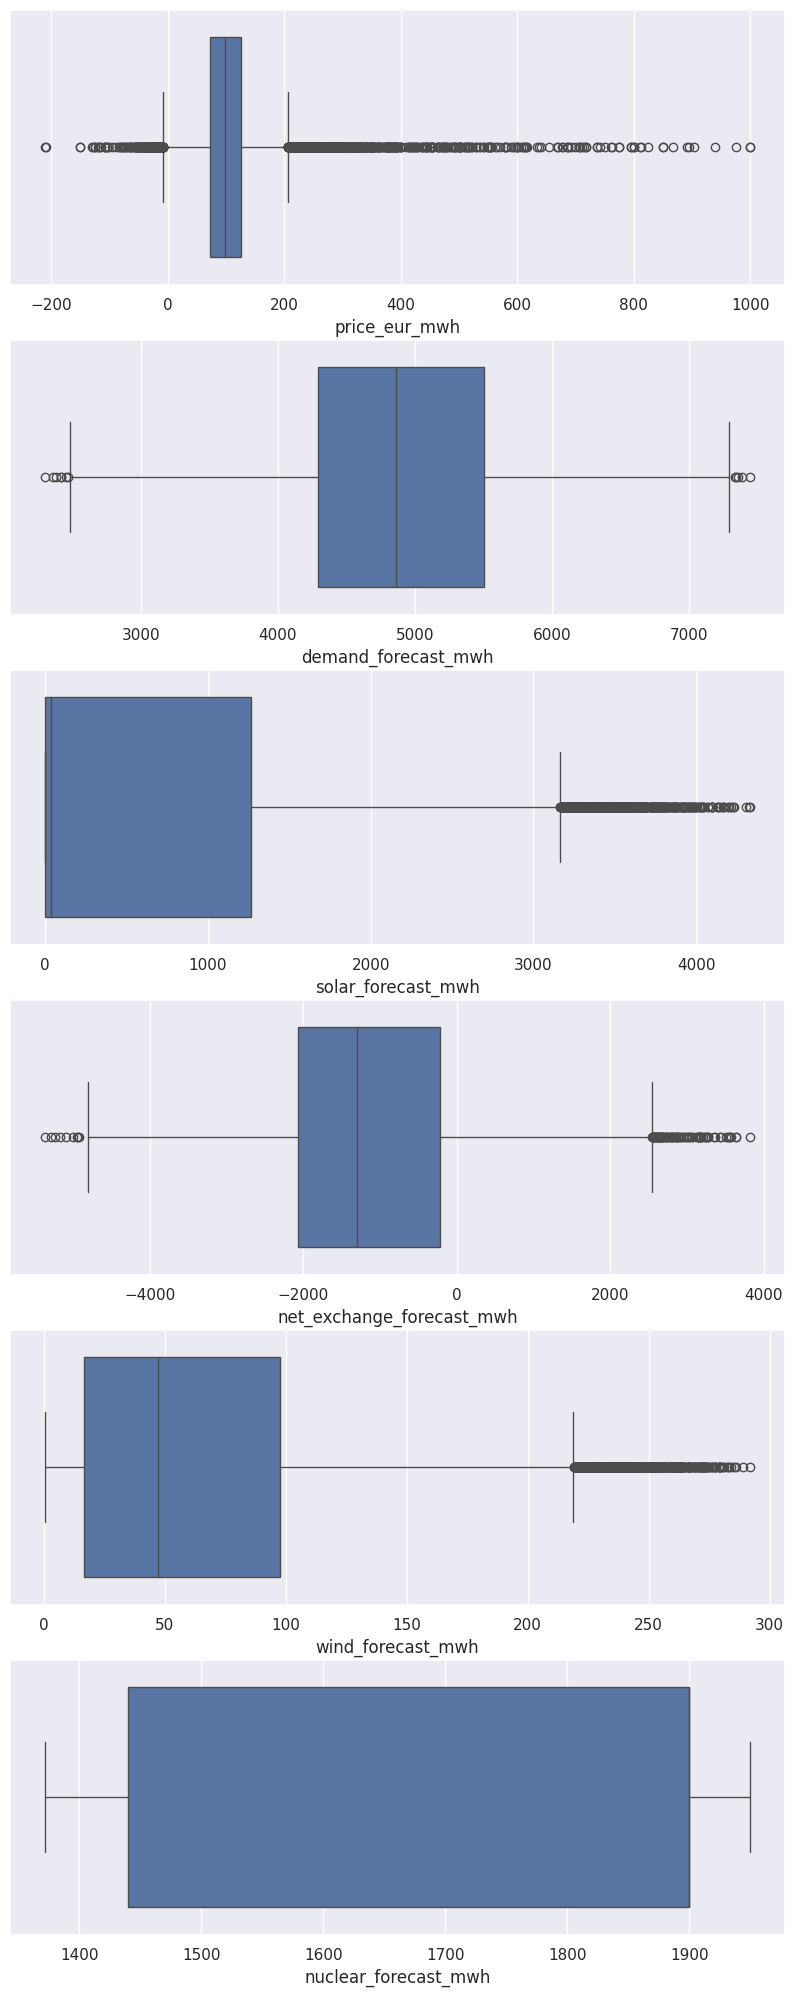

In [32]:
# Тут как в примере про гистограммы. Но на этот раз рисуем не в рамках сетки 2 на 2, а в рамках сетки 5 на 1
fig, ax = plt.subplots(nrows=6, ncols=1, figsize=(10,25))

for idx, column_name in enumerate(num_columns):

    plt.subplot(6,1, idx+1)
    sns.boxplot(data=df, # какой датафрейм используем
            x=column_name); # какую переменную используем

Можно, по хорошему еще поудалять данных

## 7 Корреляция числовых признаков

Посмотрим на корреляцию числовых столбцов

`.corr()` для получения матрицы корреляции из датафрейма (нечисловые признаки будут проигнорированы)

`.style.background_gradient(cmap, vmin, vmax)` чтобы подсветить красиво таблицу

In [33]:
cm = sns.color_palette("vlag", as_cmap=True) # создадим цветовой стиль, чтобы раскрасить табличку

df[num_columns].corr().style.background_gradient(cmap=cm, # наш цветовой стиль
                                    vmin = -1, # указываем нижний диапазон
                                    vmax=1) # указываем верхний  диапазон

,price_eur_mwh,demand_forecast_mwh,solar_forecast_mwh,net_exchange_forecast_mwh,wind_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c
price_eur_mwh,1.000000,0.588128,-0.401941,-0.427457,-0.080483,0.079333,-0.145900
demand_forecast_mwh,0.588128,1.000000,-0.267465,-0.578691,0.049818,0.040131,-0.402458
solar_forecast_mwh,-0.401941,-0.267465,1.000000,0.703014,-0.183564,-0.048918,0.462534
net_exchange_forecast_mwh,-0.427457,-0.578691,0.703014,1.000000,-0.133620,0.094415,0.435270
wind_forecast_mwh,-0.080483,0.049818,-0.183564,-0.133620,1.000000,0.031541,-0.158097
nuclear_forecast_mwh,0.079333,0.040131,-0.048918,0.094415,0.031541,1.000000,-0.114606
temperature_forecast_c,-0.145900,-0.402458,0.462534,0.435270,-0.158097,-0.114606,1.000000


# 8 Исследования временных рядов


In [35]:
# Проверим монотонность, дубликаты и пропуски
print(f'монтонность: {df.index.is_monotonic_increasing}')
print(f'дубликаты: {df.index.has_duplicates}')
print(f'пропуски: {df.isna().sum().sum()}')

монтонность: True
дубликаты: False
пропуски: 0


### Введение индексов-дат

####  Задание временной индексации

1. **Переименование колонки**:  
   Колонка `'timestamp'` переименована в `'time'` для удобства и читаемости.

2. **Преобразование к типу datetime**:  
   Преобразовали `'time'` к типу временных меток `datetime`. Это необходимо для корректной работы с временными рядами.

3. **Установка временного индекса**:  
   Колонка `'time'` установлена в качестве индекса DataFrame. Это позволяет использовать удобные методы для работы с временными данными, например:  
   - `df.loc['2025']` — выборка за 2025 год,  
   - `df.resample('D')` — агрегация по дням.
     
4. **Удаление часового пояса (UTC)**:  
   Из индекса удалён часовой пояс (например, `+00:00`), чтобы получить "наивное" время (`naive datetime`) в формате `2025-11-25 23:00:00`.  

   
   
5. **Проверка частоты данных**:  
   Убедимся, что временной индекс имеет **почасовую частоту** (`'H'`).
        
6. **Проверка**:  
   Вывод случайных 15 строк для оценки структуры данных.

In [36]:
df = df.rename(columns = {'timestamp':'time'})
df['time'] = pd.to_datetime(df['time'])
df.set_index('time', inplace=True)
df.index = df.index.tz_localize(None)
df = df.asfreq('h')

df.sample(5, random_state=0)

,price_eur_mwh,demand_forecast_mwh,solar_forecast_mwh,net_exchange_forecast_mwh,wind_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c
time,,,,,,,
2025-08-04 16:00:00,145.89,4905.08,467.18,-3193.8,77.30,1440.0,24.42
2025-01-31 13:00:00,119.97,5332.35,1191.75,134.8,77.38,1900.0,9.67
2024-06-28 11:00:00,71.53,5022.83,2530.90,-200.0,10.33,1900.0,26.72
2025-08-18 07:00:00,88.04,4138.00,2646.93,1430.7,41.18,1440.0,21.59
2024-01-31 16:00:00,122.97,6695.33,0.00,-2673.7,6.13,1900.0,0.87


#### проверка регулярности шагов временной метки

In [37]:
dt = df.index.to_series().diff().value_counts()
print(dt.head())

time
0 days 01:00:00    17543
Name: count, dtype: int64


#### диапазон дат

In [38]:
print(f"Диапазон дат: {df.index.min()} — {df.index.max()}")
print(f"Частота (если установлена): {df.index.freq}")

Диапазон дат: 2023-12-31 23:00:00 — 2025-12-31 22:00:00
Частота (если установлена): <Hour>


## Визуализация временного ряда

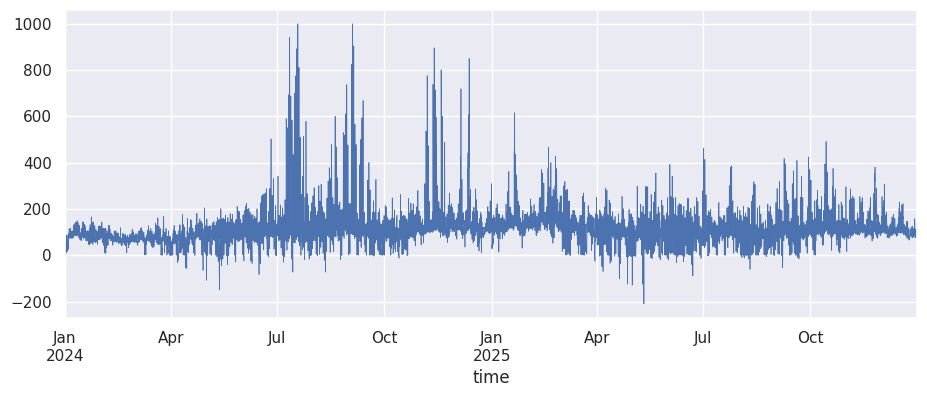

In [39]:
# Письмаров
df['price_eur_mwh'].plot(linewidth=0.5);

Также визуализируем и остальные столбцы

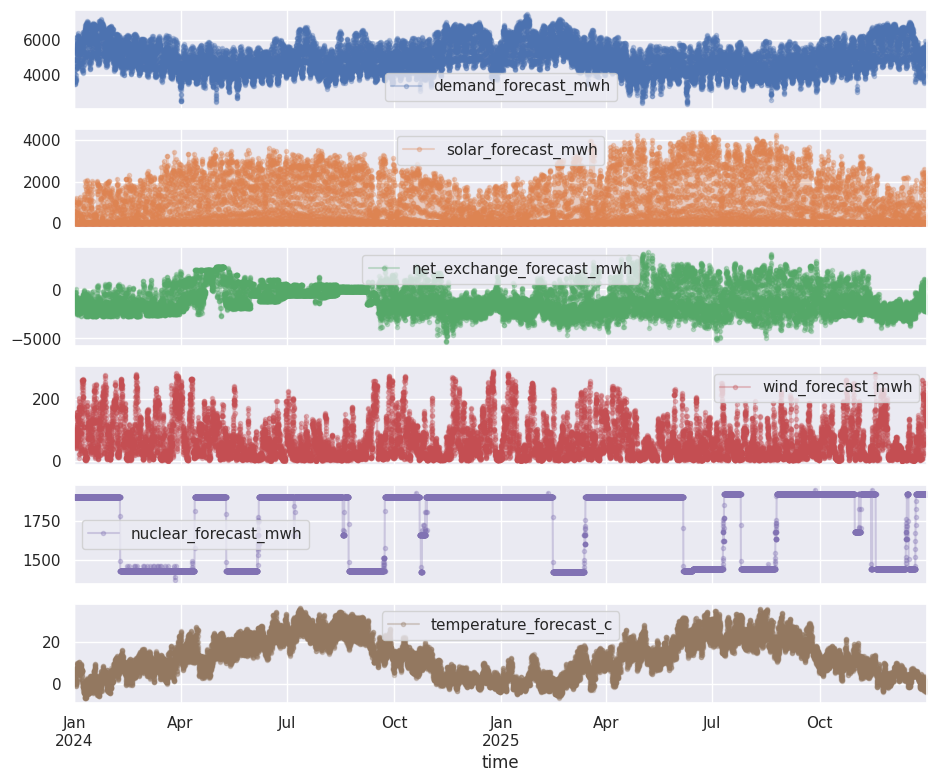

In [46]:
cols_plot = ['demand_forecast_mwh', 'solar_forecast_mwh', 'net_exchange_forecast_mwh','wind_forecast_mwh','nuclear_forecast_mwh', 'temperature_forecast_c']
axes = df[cols_plot].plot(marker='.', alpha=0.3, linestyle='-', figsize=(11, 9), subplots=True)
# for ax,col in axes:
#     ax.set_ylabel('Daily Totals (GWh)')

### Визуализация на одном графике, с периодом 1 месяц относительно экзогенного фактора - температура

/tmp/ipykernel_1253/1503538436.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df_monthly_energy = df[['demand_forecast_mwh', 'solar_forecast_mwh', 'wind_forecast_mwh', 'nuclear_forecast_mwh']].resample('M').sum(min_count=1)
/tmp/ipykernel_1253/1503538436.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  df_monthly_temp = df[['temperature_forecast_c']].resample('M').mean()  # среднее значение температуры за месяц
/usr/local/lib/python3.13/dist-packages/pandas/plotting/_matplotlib/core.py:981: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


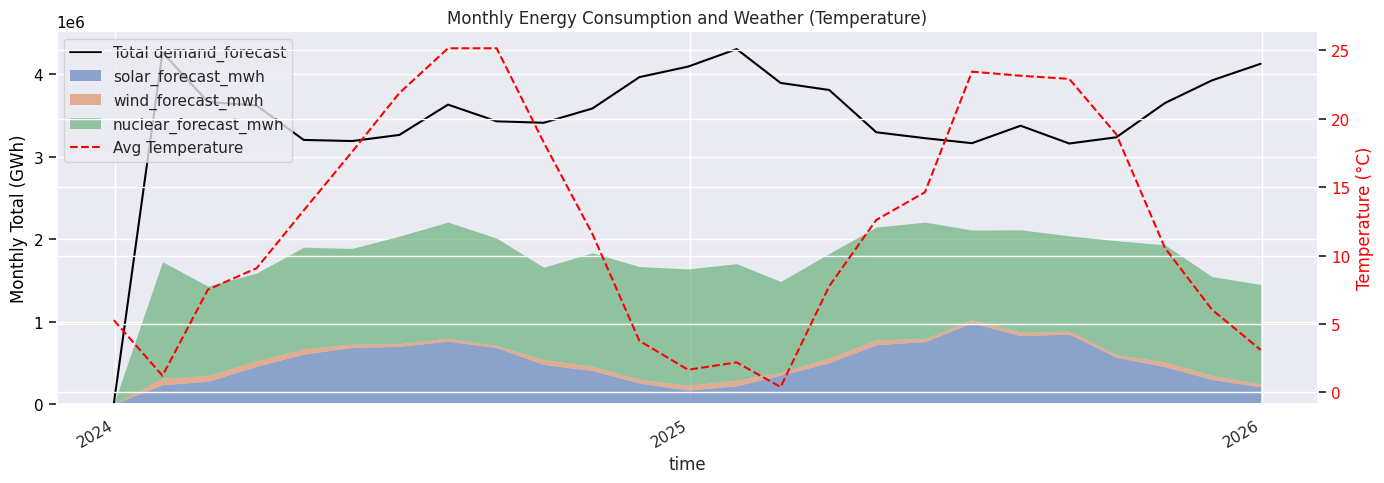

In [48]:
# Агрегация по месяцам: сумма для энергии, среднее для температуры
df_monthly_energy = df[['demand_forecast_mwh', 'solar_forecast_mwh', 'wind_forecast_mwh', 'nuclear_forecast_mwh']].resample('M').sum(min_count=1)
df_monthly_temp = df[['temperature_forecast_c']].resample('M').mean()  # среднее значение температуры за месяц
df_monthly = df_monthly_energy.join(df_monthly_temp)

fig, ax1 = plt.subplots(figsize=(14, 5))

# Основной график: потребление
ax1.plot(df_monthly['demand_forecast_mwh'], color='black', label='Total demand_forecast')
ax1.set_ylabel('Monthly Total (GWh)', color='black')
ax1.tick_params(axis='y', labelcolor='black')

# Область: генерация ВИЭ
df_monthly[['solar_forecast_mwh', 'wind_forecast_mwh', 'nuclear_forecast_mwh']].plot.area(ax=ax1, linewidth=0, alpha=0.6)

# Вторая ось Y для температуры
ax2 = ax1.twinx()
ax2.plot(df_monthly['temperature_forecast_c'], color='red', linestyle='--', label='Avg Temperature')
ax2.set_ylabel('Temperature (°C)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Форматирование оси X
ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Легенда
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.title('Monthly Energy Consumption and Weather (Temperature)')
plt.tight_layout()
plt.show();

### Интерактивная визуализация

In [51]:
# Подготовка данных
df_viz = df[['demand_forecast_mwh', 'temperature_forecast_c']].copy()
df_viz['demand_forecast_mwh_rolling_7d'] = df_viz['demand_forecast_mwh'].rolling(24*7, min_periods=1).mean()

# Создаём подграфики с двумя осями Y
fig = make_subplots(specs=[[{"secondary_y": True}]])

# Правая ось: температура
fig.add_trace(
    go.Scatter(x=df_viz.index, y=df_viz['temperature_forecast_c'], name='temperature_forecast_c',
               line=dict(color='red', dash='dash'), opacity=0.7),
    secondary_y=True,
)

# Левая ось: потребление
fig.add_trace(
    go.Scatter(x=df_viz.index, y=df_viz['demand_forecast_mwh'], name='Actual demand_forecast_mwh',
               line=dict(color='blue', width=1), opacity=0.97),
    secondary_y=False,
)

# Левая ось: скользящее среднее
fig.add_trace(
    go.Scatter(x=df_viz.index, y=df_viz['demand_forecast_mwh_rolling_7d'], name='7-Day Rolling Mean',
               line=dict(color='black', dash='dot', width=3), opacity=0.99),
    secondary_y=False,
)

# Настройка осей
fig.update_layout(title="demand_forecast_mwh with Rolling Mean & temperature_forecast_c (Dual Axis)")
fig.update_xaxes(title_text="Time")
fig.update_yaxes(title_text="GWh", secondary_y=False, side='left')
fig.update_yaxes(title_text="temperature_forecast_c (°C)", secondary_y=True, side='right')

fig.show()

### Оценка влияния температуры на показания

/tmp/ipykernel_1253/2355455450.py:7: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.

/tmp/ipykernel_1253/2355455450.py:8: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



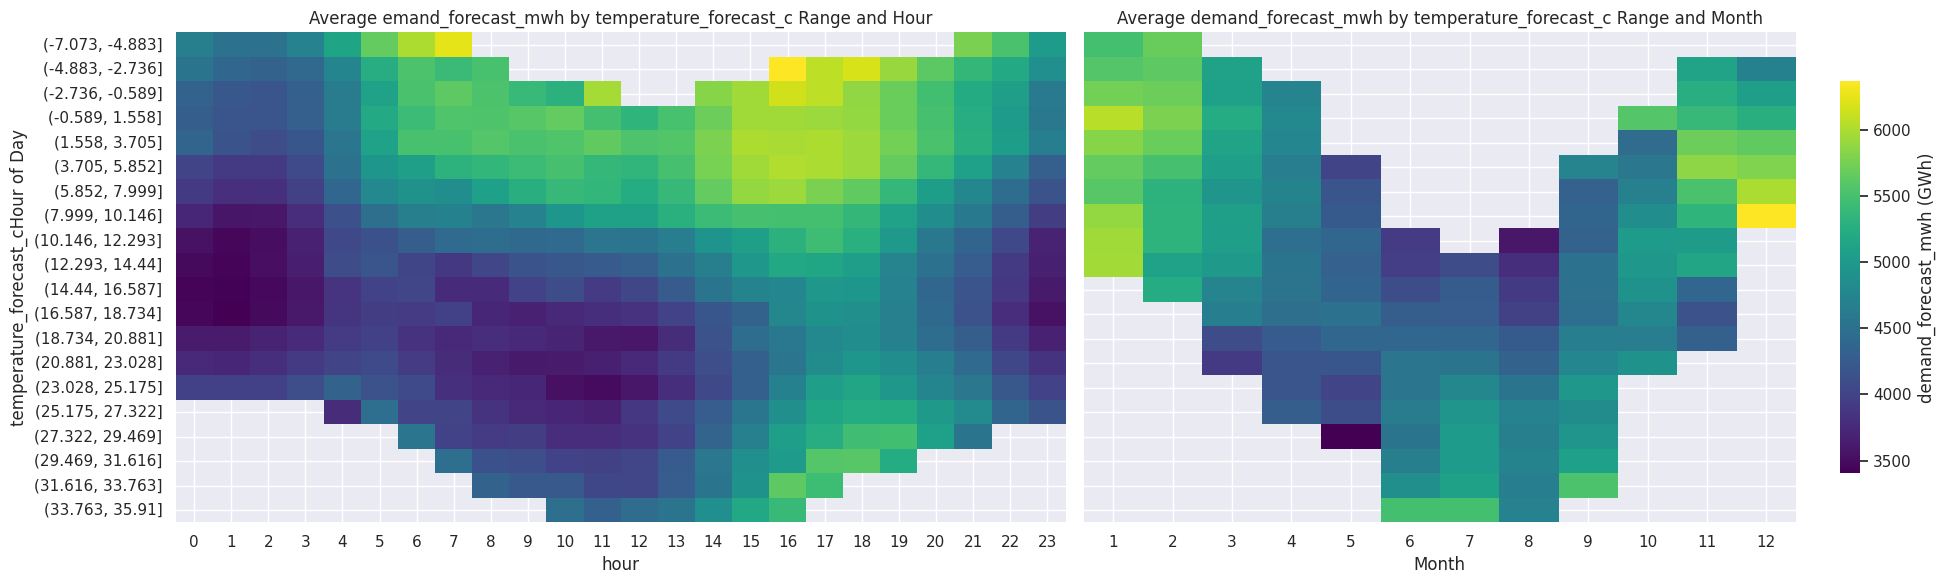

In [52]:
# Подготовка данных
df['temp_bin'] = pd.cut(df['temperature_forecast_c'], bins=20)
df['hour'] = df.index.hour
df['month'] = df.index.month

# Данные для двух графиков
heatmap_hour = df.groupby(['temp_bin', 'hour'])['demand_forecast_mwh'].mean().unstack(fill_value=0)
heatmap_month = df.groupby(['temp_bin', 'month'])['demand_forecast_mwh'].mean().unstack(fill_value=0)

# Создаём 2 сабплота горизонтально с общей осью Y и общей цветовой шкалой
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 6), sharey=True)

# График 1: по часам
sns.heatmap(heatmap_hour, cmap='viridis',  ax=ax1, cbar=False)
ax1.set_title('Average emand_forecast_mwh by temperature_forecast_c Range and Hour')
ax1.set_ylabel('temperature_forecast_cHour of Day')

# График 2: по месяцам
sns.heatmap(heatmap_month, cmap='viridis',  ax=ax2, cbar_kws={'label': 'demand_forecast_mwh (GWh)', 'shrink': 0.8})
ax2.set_title('Average demand_forecast_mwh by temperature_forecast_c Range and Month')
ax2.set_ylabel('')  # Убираем подпись оси Y для второго графика
ax2.set_xlabel('Month')

plt.tight_layout()
plt.show()

Также важно понять как быстро происходит реакция потребления на температуру. Для этого можно посчитать корреляцию со сдвинутой копией ряда потребления. То есть лаговую корреляцию. Максимум по модулю этой величины покажет когда и насколько хорошо потребление реагирует на изменение температуры

Важно понимать, что корреляция по лагам не причинность и может быть:
* завышена сезонностью
* смазана суточным циклом

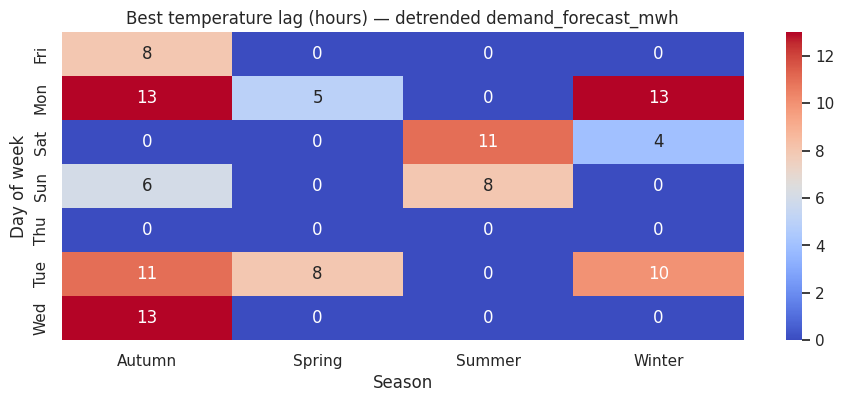

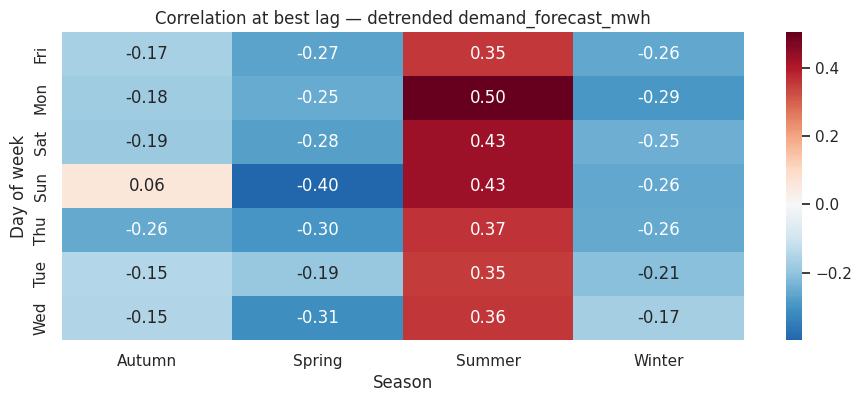

In [54]:
df['day_of_week'] = pd.to_datetime(df.index).dayofweek
# Дедтренд: убираем сезон и суточный цикл
df['demand_forecast_mwh_detrended'] = df['demand_forecast_mwh'] - df.groupby(['month', 'hour'])['demand_forecast_mwh'].transform('mean')

# Определяем сезоны
season_map = {1: 'Winter', 2: 'Spring', 3: 'Summer', 4: 'Autumn'}
df['season'] = df['month'].map(lambda m: (m%12 + 3)//3).map(season_map)

# Подписи дней недели
dow_map = {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri', 5: 'Sat', 6: 'Sun'}
df['day_of_week_str'] = df['day_of_week'].map(dow_map)

# Параметры лагов
max_lag = 13
lags = range(0, max_lag + 1)

results = []

# Вычисляем корреляцию по сезону и дню недели
for season in df['season'].unique():
    for dow in df['day_of_week_str'].unique():
        sub = df[(df['season'] == season) & (df['day_of_week_str'] == dow)]
        if len(sub) < 30:
            continue

        corrs = [sub['demand_forecast_mwh_detrended'].corr(sub['temperature_forecast_c'].shift(lag)) for lag in lags]
        corrs_smoothed = pd.Series(corrs).rolling(3, center=True, min_periods=1).mean()

        best_lag = corrs_smoothed.abs().idxmax()
        best_corr = corrs_smoothed[best_lag]

        results.append({
            'season': season,
            'day_of_week': dow,
            'best_lag': best_lag,
            'corr': best_corr
        })

best_lags_df = pd.DataFrame(results)


# Heatmap: лучший лаг
pivot_lag = best_lags_df.pivot(index='day_of_week', columns='season', values='best_lag')
sns.heatmap(pivot_lag, annot=True, cmap='coolwarm', fmt='.0f')
plt.title('Best temperature lag (hours) — detrended demand_forecast_mwh')
plt.xlabel('Season')
plt.ylabel('Day of week')
plt.show()

# Heatmap: сила корреляции
pivot_corr = best_lags_df.pivot(index='day_of_week', columns='season', values='corr')
sns.heatmap(pivot_corr, annot=True, cmap='RdBu_r', center=0, fmt='.2f')
plt.title('Correlation at best lag — detrended demand_forecast_mwh')
plt.xlabel('Season')
plt.ylabel('Day of week')
plt.show()

## Оценка сезонных составляющих

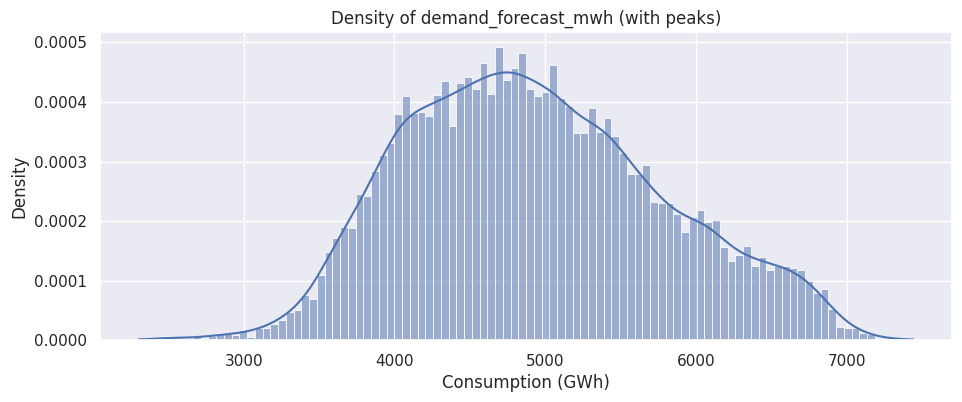

In [55]:
# Для общего потребления
sns.histplot(df['demand_forecast_mwh'], kde=True, stat='density', bins=100)
plt.title('Density of demand_forecast_mwh (with peaks)')
plt.xlabel('Consumption (GWh)')
plt.ylabel('Density')
plt.show()


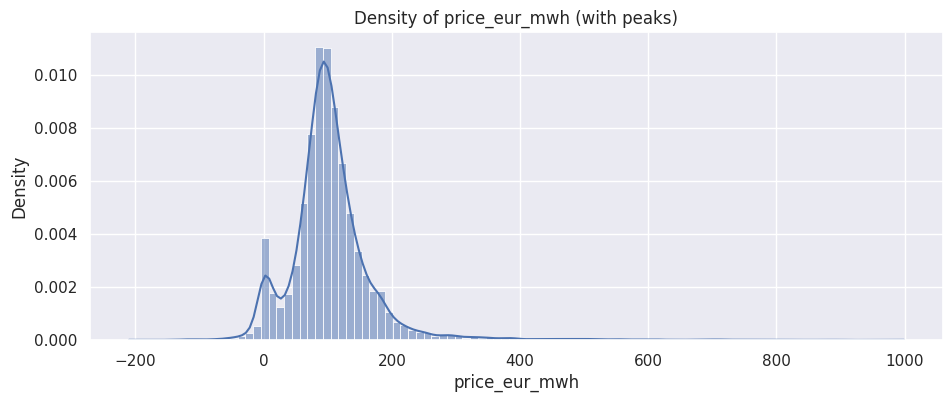

In [66]:
# Для цены
sns.histplot(df['price_eur_mwh'], kde=True, stat='density', bins=100)
plt.title('Density of price_eur_mwh (with peaks)')
plt.xlabel('price_eur_mwh')
plt.ylabel('Density')
plt.show()


* Посмотрим в какие месяцы потребление высокое/низкое → зима vs лето.
* Посмотрим в какое время суток пик нагрузки → утро и вечер (типичный "пик потребления").
* Проверим в какие дни  пик нагрузки → будни vs выходные.

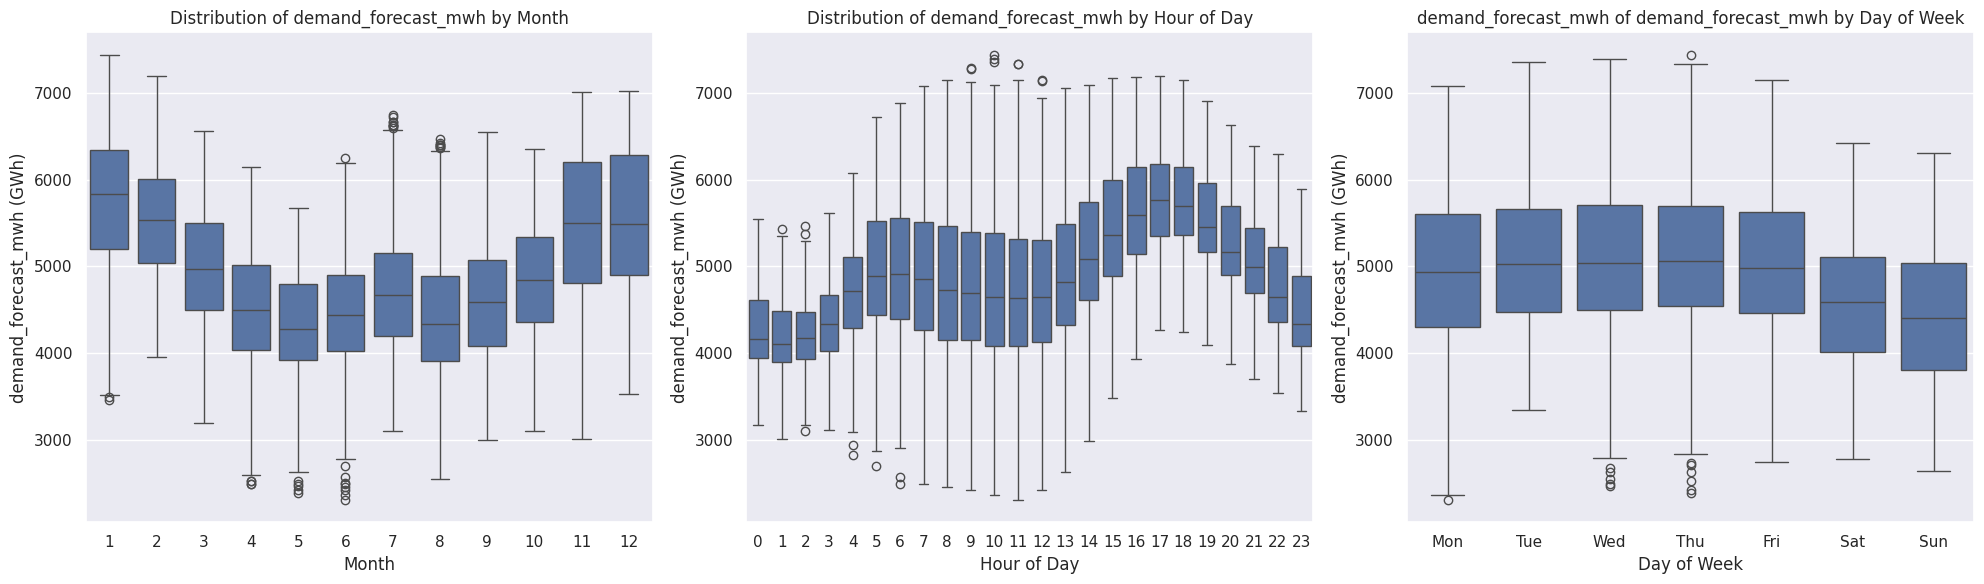

In [70]:
# Для общего потребления
# Подготовка данных
df['month'] = df.index.month
df['hour'] = df.index.hour
df['day_of_week'] = df.index.dayofweek  # 0=понедельник, 6=воскресенье

# Создаём 3 сабплота горизонтально
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

# График 1: по месяцам
sns.boxplot(x='month', y='demand_forecast_mwh', data=df, ax=ax1)
ax1.set_title('Distribution of demand_forecast_mwh by Month')
ax1.set_xlabel('Month')
ax1.set_ylabel('demand_forecast_mwh (GWh)')

# График 2: по часам
sns.boxplot(x='hour', y='demand_forecast_mwh', data=df, ax=ax2)
ax2.set_title('Distribution of demand_forecast_mwh by Hour of Day')
ax2.set_xlabel('Hour of Day')
ax2.set_ylabel('demand_forecast_mwh (GWh)')

# График 3: по дням недели
sns.boxplot(x='day_of_week', y='demand_forecast_mwh', data=df, ax=ax3)
ax3.set_title('demand_forecast_mwh of demand_forecast_mwh by Day of Week')
ax3.set_xlabel('Day of Week')
ax3.set_ylabel('demand_forecast_mwh (GWh)')
ax3.set_xticks(range(7))
ax3.set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])

plt.tight_layout()
plt.show()

### Проверим потребление в дневное и ночное время по месяцам

<Axes: xlabel='day_of_week', ylabel='hour'>

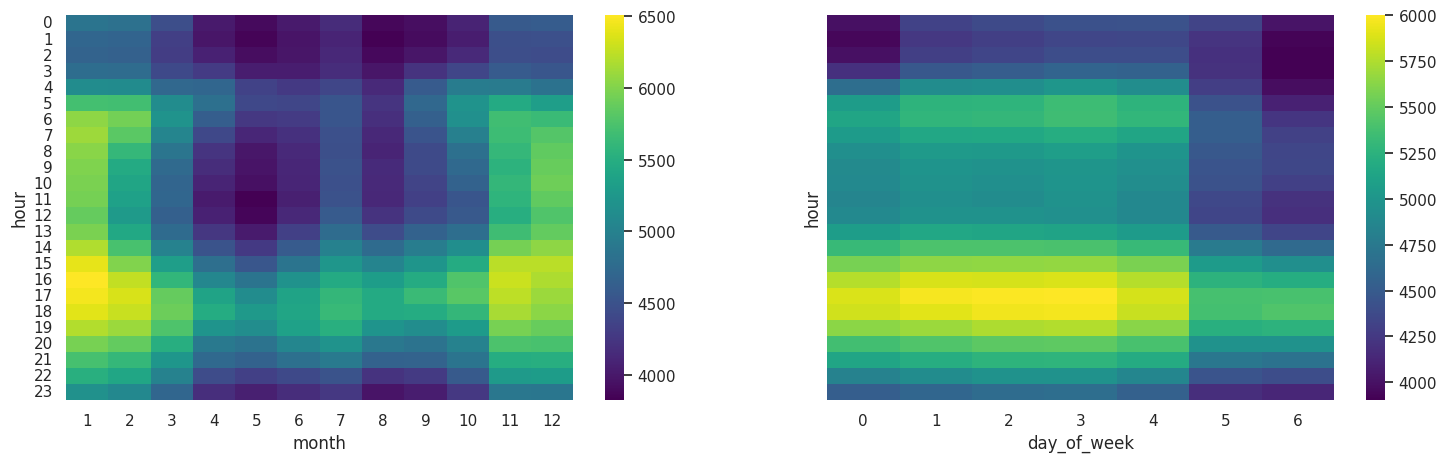

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)

pivot = df.pivot_table(
    values='demand_forecast_mwh',
    index='hour',
    columns='month',
    aggfunc='mean'
)

sns.heatmap(pivot, cmap='viridis', ax = axes[0])



pivot_h_dow = df.pivot_table(
    values='demand_forecast_mwh',
    index='hour',
    columns='day_of_week',
    aggfunc='mean'
)

sns.heatmap(pivot_h_dow, cmap='viridis', ax = axes[1])

* Посмотрим в какие месяцы цена высокая/низкая → зима vs лето.
* Посмотрим в какое время суток пик цены → утро и вечер
* Проверим в какие дни  пик цены → будни vs выходные.

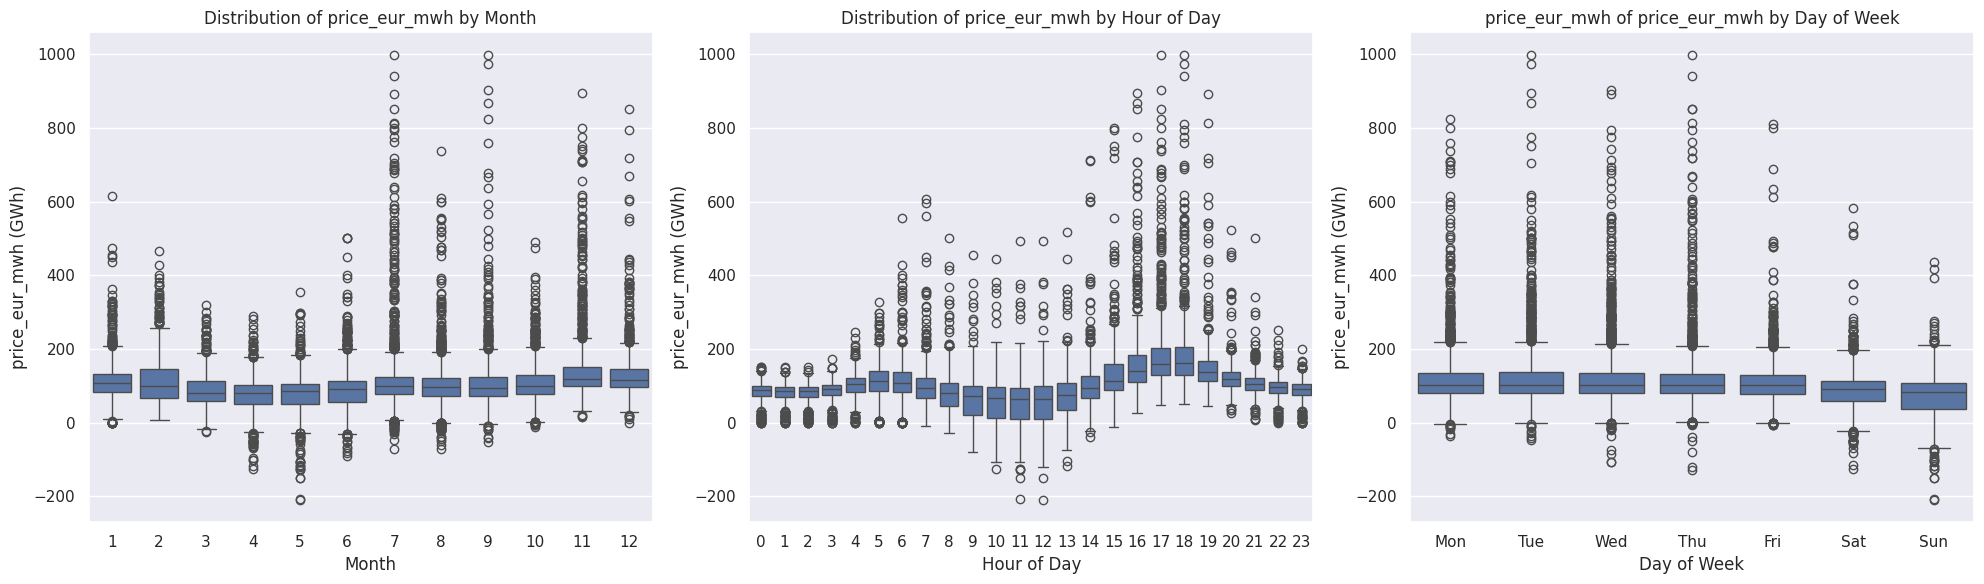

In [69]:
# Подготовка данных
df['month'] = df.index.month
df['hour'] = df.index.hour
df['day_of_week'] = df.index.dayofweek  # 0=понедельник, 6=воскресенье

# Создаём 3 сабплота горизонтально
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

# График 1: по месяцам
sns.boxplot(x='month', y='price_eur_mwh', data=df, ax=ax1)
ax1.set_title('Distribution of price_eur_mwh by Month')
ax1.set_xlabel('Month')
ax1.set_ylabel('price_eur_mwh (GWh)')

# График 2: по часам
sns.boxplot(x='hour', y='price_eur_mwh', data=df, ax=ax2)
ax2.set_title('Distribution of price_eur_mwh by Hour of Day')
ax2.set_xlabel('Hour of Day')
ax2.set_ylabel('price_eur_mwh (GWh)')

# График 3: по дням недели
sns.boxplot(x='day_of_week', y='price_eur_mwh', data=df, ax=ax3)
ax3.set_title('price_eur_mwh of price_eur_mwh by Day of Week')
ax3.set_xlabel('Day of Week')
ax3.set_ylabel('price_eur_mwh (GWh)')
ax3.set_xticks(range(7))
ax3.set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])

plt.tight_layout()
plt.show()

### Проверим цену в дневное и ночное время по месяцам



<Axes: xlabel='day_of_week', ylabel='hour'>

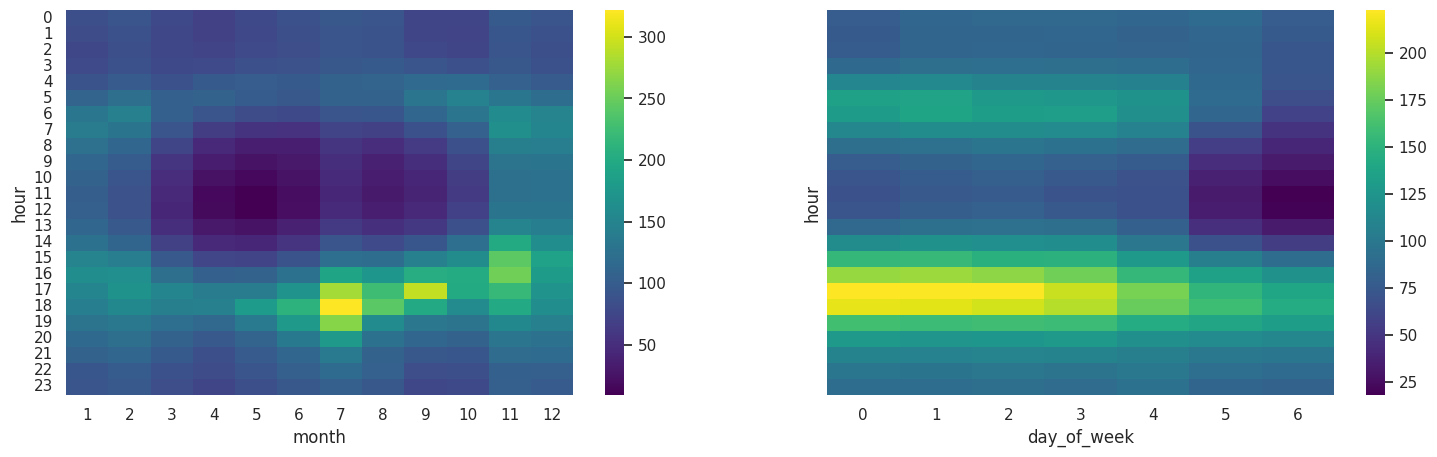

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5), sharey=True)

pivot = df.pivot_table(
    values='price_eur_mwh',
    index='hour',
    columns='month',
    aggfunc='mean'
)

sns.heatmap(pivot, cmap='viridis', ax = axes[0])



pivot_h_dow = df.pivot_table(
    values='price_eur_mwh',
    index='hour',
    columns='day_of_week',
    aggfunc='mean'
)

sns.heatmap(pivot_h_dow, cmap='viridis', ax = axes[1])

### Анализ редких регулярных событий

### Для потребления

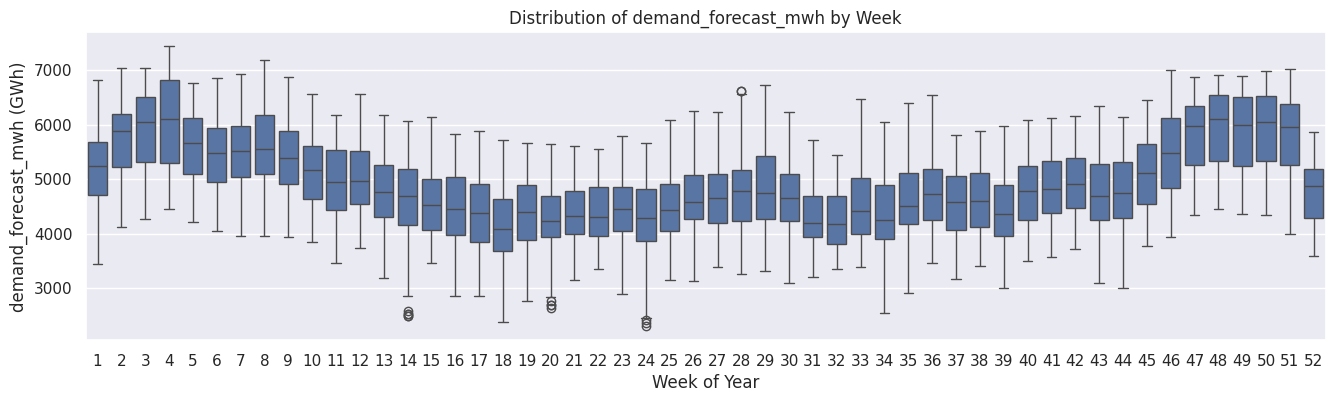

In [61]:
# Для потребления
df['week'] = df.index.isocalendar().week  # номер недели в году

# Создаём 2 сабплота горизонтально
fig, ax1 = plt.subplots(1, 1, figsize=(16, 4))


# График 2: по неделям
sns.boxplot(x='week', y='demand_forecast_mwh', data=df, ax=ax1)
ax1.set_title('Distribution of demand_forecast_mwh by Week')
ax1.set_xlabel('Week of Year')
ax1.set_ylabel('demand_forecast_mwh (GWh)')

plt.show()

### Для цены

Text(0, 0.5, 'price_eur_mwh (GWh)')

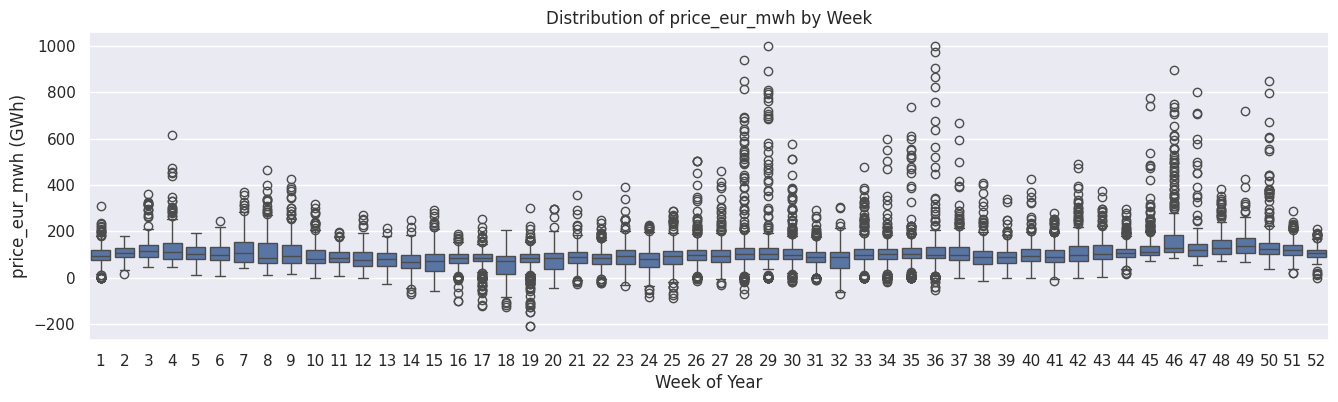

In [73]:
# Для цены
df['week'] = df.index.isocalendar().week  # номер недели в году

# Создаём 2 сабплота горизонтально
fig, ax1 = plt.subplots(1, 1, figsize=(16, 4))


# График 2: по неделям
sns.boxplot(x='week', y='price_eur_mwh', data=df, ax=ax1)
ax1.set_title('Distribution of price_eur_mwh by Week')
ax1.set_xlabel('Week of Year')
ax1.set_ylabel('price_eur_mwh (GWh)')

Спад потребления связан с выходными. Однако, Потребление во время смены года можно считать или аномалией или третьей составляющей (что возможно правильней). Проверим гипотезу о 3 составляющей. Для этого используем скользящее среднее.

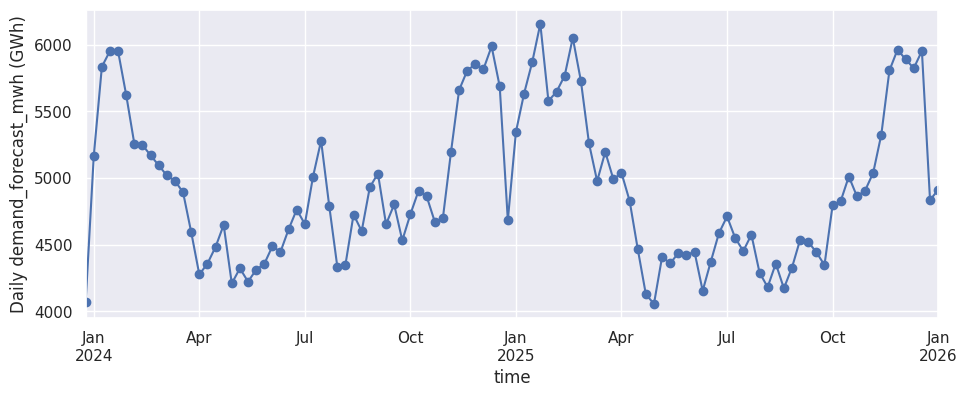

In [62]:
# Диапазон дат: 2023-12-31 23:00:00 — 2025-12-31 22:00:00
ax = df.loc['2023-12':'2025-12', 'demand_forecast_mwh'].\
    resample('W').mean().plot(marker='o', linestyle='-',linewidth=1.5)
ax.set_ylabel('Daily demand_forecast_mwh (GWh)')
plt.show()

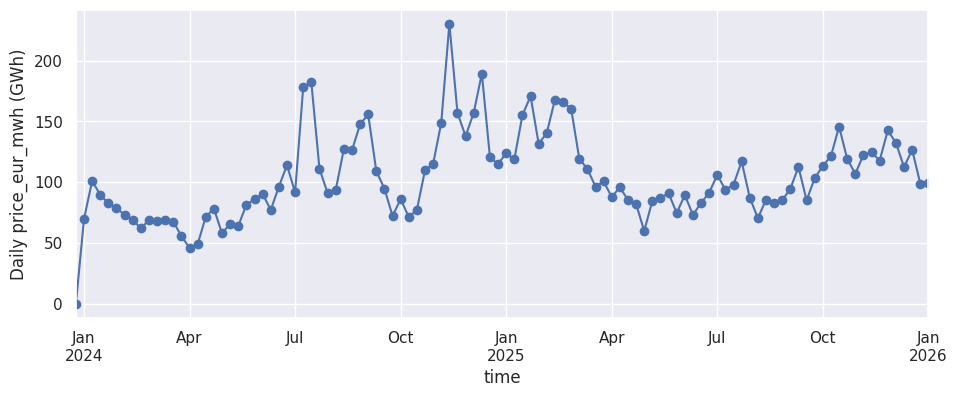

In [74]:
# Диапазон дат: 2023-12-31 23:00:00 — 2025-12-31 22:00:00
ax = df.loc['2023-12':'2025-12', 'price_eur_mwh'].\
    resample('W').mean().plot(marker='o', linestyle='-',linewidth=1.5)
ax.set_ylabel('Daily price_eur_mwh (GWh)')
plt.show()

В целом, подтвердить гипотезу о holidays можно и по другому, например при помощи библиотеки `holidays`

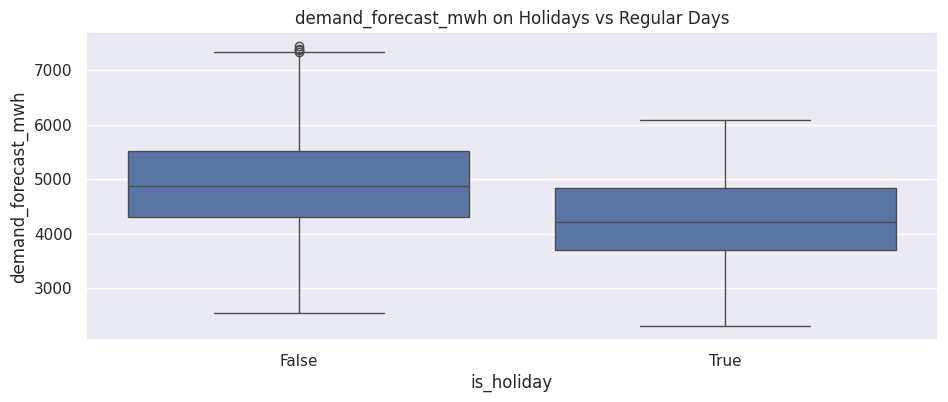

In [64]:
import holidays

# Пример для Венгрии
de_holidays = holidays.DE(years=df.index.year.unique())

# Используем .apply() для Series или .map() для Series
df['is_holiday'] = df.index.to_series().dt.date.apply(lambda x: x in de_holidays)

# Визуализация
sns.boxplot(data=df, x='is_holiday', y='demand_forecast_mwh')
plt.title('demand_forecast_mwh on Holidays vs Regular Days')
plt.show()

И так, у нас имеет место 2 основных сезонности - годовая и недельная и регулярное но редкое событие - окончание каждого год

### Оценка тренда

Тренд для потребления

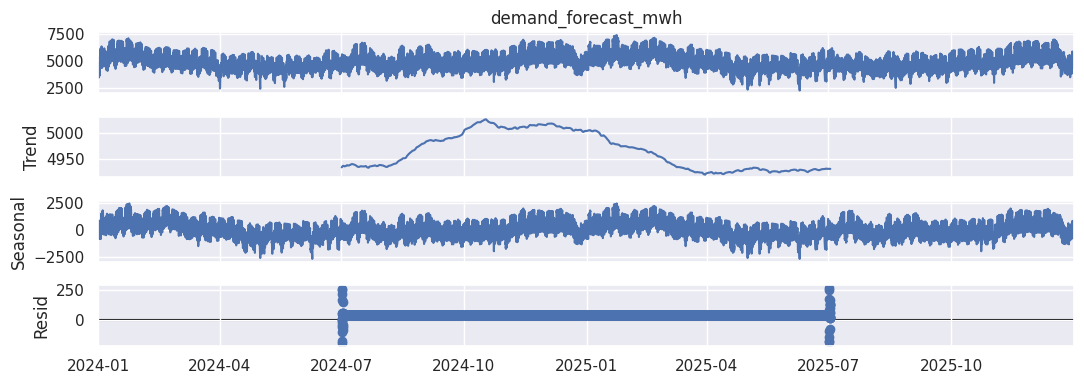

In [65]:
decomp = seasonal_decompose(df['demand_forecast_mwh'], model='additive', period=24*365//1)  # 1 год = 8760 часов
decomp.plot()
plt.tight_layout()
plt.show()

Тренд для цены

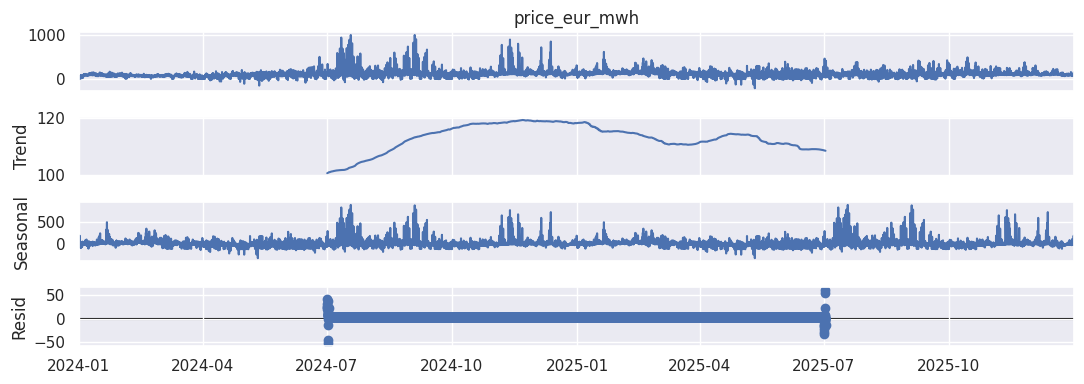

In [75]:
decomp = seasonal_decompose(df['price_eur_mwh'], model='additive', period=24*365//1)  # 1 год = 8760 часов
decomp.plot()
plt.tight_layout()
plt.show()